# Video properties: P and H comparisons

Calculate all stimulus videos from their extracted frames, using the color/RMS definitions from [calculateVideoValues.m](https://github.com/rhernandez00/Comparative-study-of-dog-vision/blob/main/videoSelection/calculateVideoValues.m), a Python reproduction of its three-step block-motion method, and Farneback dense flow from `C:\github\Networks\dense_optical_flow_to_fsl.py`.

Folders encode run, species, emotion, and video number: **R1DogP1** = run 1, dog, positive anticipation, video 1. **H = happiness; F = fear.** All five emotions are measured; only P and H are plotted. Only happiness and positive anticipation enter statistical tests.

Each **unique clip** contributes one observation. Exact repeated sequences across runs are measured but counted once in bars, SEMs, and tests. All 240 folders contain 160 unique clips (16 per species/emotion group). Bars show mean ± SEM across unique clips, with individual clip points. Source-video metadata supplies verified fps and frame counts. Inputs are read only. See `VIDEO_PROPERTIES.md` for full methods and assumptions.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Image, Markdown

# Open this notebook from the repository, or set PROJECT explicitly.
PROJECT = Path.cwd()
if not (PROJECT / 'stimulus_video_properties.py').is_file():
    PROJECT = next(p for p in PROJECT.parents if (p / 'stimulus_video_properties.py').is_file())
sys.path.insert(0, str(PROJECT))
import importlib
import stimulus_video_properties as analysis
analysis = importlib.reload(analysis)  # Pick up edits even in an existing kernel.
print('Python:', sys.executable)
print('Project:', PROJECT)

Python: C:\ProgramData\anaconda3\python.exe
Project: C:\github\dog_brain_toolkit


## Controls: paths, computation, and plot colors
Edit the controls below, then Run All. Existing measurements are loaded by default so color changes do not repeat optical flow. Set `RECOMPUTE_MEASUREMENTS = True` to rescan inputs and validate/reuse video caches, or also set `FORCE = True` to remeasure every frame. If original videos are unavailable, set `FPS` only to a verified extraction frame rate. Colors accept hex codes or Matplotlib color names.

In [2]:
FRAMES = Path(r'G:\My Drive\Networks\stimuli_by_frames')
SOURCE_VIDEOS = Path(r'C:\github\Networks\paradigm\stimuli')
FIGURE_DIRECTORY = Path(r'G:\My Drive\Results\Positive-Happiness\Figure_A')
OUTPUT = PROJECT / 'outputs' / 'video_properties'
WORKERS = 4
MAX_FLOW_DIMENSION = 640
FPS = None  # None = matching source-video metadata
RECOMPUTE_MEASUREMENTS = False
FORCE = False

# P/H plot colors (pooled species).
EMOTION_COLORS = {'P': '#2b9b8f', 'H': '#e8b84c'}
# Four species/emotion bars.
GROUP_COLORS = {
    'DogP': '#2b9b8f', 'DogH': '#e8b84c',
    'HumP': '#2b9b8f', 'HumH': '#e8b84c',
}
# Per-subplot overrides, e.g. brightness: {'P': 'navy', 'H': 'gold'}.
PROPERTY_COLORS = {
    'hue': {}, 'saturation': {}, 'brightness': {}, 'contrast_rms': {},
    'dense_flow_pixels_per_frame': {},
}
POINT_COLOR = '#202b33'
ERROR_BAR_COLOR = '#303030'
BACKGROUND_COLOR = 'white'

# Typography, line weights, and compact layout.
FONT_SIZE = 10
LINE_WIDTH = 0.8       # Axes, ticks, grid, bar edges, and error bars (points).
BAR_GAP = 0.3        # Empty space between adjacent bar edges, in x-axis units.
SHOW_LEGEND = False
BAR_WIDTH = 0.155     # One quarter of the previous 0.62 width.
FIGURE_SIZE = (10, 6) # Width, height in inches.
SHOW_TITLES = False
SHOW_SUBTITLES = False # Statistical annotations; full tests remain in tables.
OUTPUT

WindowsPath('C:/github/dog_brain_toolkit/outputs/video_properties')

Plots show hue, saturation, brightness, RMS contrast, dense optical flow displacement. Block motion, frame count, and dense optical flow speed are excluded from plots. Stored measurements and statistical tables retain all outcomes.

**RMS intensity** (previously “Raw grayscale RMS”) is `sqrt(mean(gray**2))`, averaged across frames. Gray values range from 0 to 255. This reproduces the original MATLAB definition, but it does not subtract mean brightness and therefore is not a pure measure of contrast. The standard deviation of grayscale intensity would instead measure mean-centered RMS contrast. Movement is the spatial and temporal mean optical-flow magnitude, in resized pixels per frame. Positive anticipation is teal (`#2b9b8f`); happiness is gold (`#e8b84c`).

## Measurement definitions

Hue and saturation: arithmetic pixel means of HSV channels, averaged equally across frames. Brightness: mean rounded MATLAB grayscale (0–255). Original RMS contrast: `sqrt(mean(gray**2))`, without subtracting mean brightness.

Block motion: 35×35 MSE three-step search, ±7-pixel maximum displacement, sum of **squared** displacement over blocks and transitions. A per-transition version is also provided. **The Python block matcher uses explicit zero-padded edge blocks and center-first ties; numerical equivalence to MATLAB has not been validated.**

Dense flow: spatial mean Farneback magnitude, averaged over N−1 transitions, using the supplied script's grayscale, INTER_AREA resizing, and parameters `(0.5, 3, 15, 3, 5, 1.2, 0)`. Displacement is in resized pixels/frame. Speed is `100 × magnitude / resized_diagonal × fps`, in % diagonal/s. No z-scoring. Frame count and `N/fps` duration are also analyzed.

All images are decoded at their stored resolution for color and block motion. Only dense flow is resized. JPEG frame recompression can cause small differences from analysis of the original videos.

In [3]:
measurement_csv = OUTPUT / 'video_properties.csv'
if measurement_csv.is_file() and not RECOMPUTE_MEASUREMENTS and not FORCE:
    videos = pd.read_csv(measurement_csv)
    print('Loaded saved measurements:', measurement_csv)
else:
    videos = analysis.analyze_dataset(
        FRAMES, SOURCE_VIDEOS, OUTPUT, workers=WORKERS,
        max_dimension=MAX_FLOW_DIMENSION, fps=FPS, force=FORCE,
    )
all_measurements = videos.copy()
videos = videos.loc[videos.emotion.isin(['P', 'H'])].copy()
print(f'Selected P/H: {len(videos)} video folders / {videos.number_of_frames.sum():,} frames')
unique_videos = analysis.independent_videos(videos)
print(f'Plot/statistical sample: {len(unique_videos)} unique clips')
display(videos.head())

Loaded saved measurements: C:\github\dog_brain_toolkit\outputs\video_properties\video_properties.csv
Selected P/H: 96 video folders / 8,640 frames
Plot/statistical sample: 64 unique clips


,video_id,run,species,emotion,emotion_name,video_number,group,source_video,source_frame_count,source_width,...,duration_seconds,width,height,flow_width,flow_height,sequence_sha256,block_motion_total,block_motion_mean_per_transition,dense_flow_pixels_per_frame,dense_flow_percent_diagonal_per_second
8,R1DogH1,1,Dog,H,Happiness,1,DogH,C:\github\Networks\paradigm\stimuli\R1DogH1.mp4,73,1080,...,2.433333,1080,1080,640,640,8543748ac1430e5ec1f058d62e360c03f160e3fbe74ddc...,4261481.0,59187.236111,11.266318,37.342920
9,R1DogH2,1,Dog,H,Happiness,2,DogH,C:\github\Networks\paradigm\stimuli\R1DogH2.mp4,57,1080,...,1.900000,1080,1080,640,640,86cffe2b6c97bf9eb8c8986859210887377842769a6000...,3152394.0,56292.750000,4.129583,13.687763
10,R1DogH3,1,Dog,H,Happiness,3,DogH,C:\github\Networks\paradigm\stimuli\R1DogH3.mp4,138,1080,...,4.600000,1080,1080,640,640,ff37efed28352e0dd52307401126c6c64ca5b1d4d1c100...,4256678.0,31070.642336,1.753954,5.813591
11,R1DogH4,1,Dog,H,Happiness,4,DogH,C:\github\Networks\paradigm\stimuli\R1DogH4.mp4,92,1080,...,3.066667,1080,1080,640,640,e1467ea7be542f06713722726f823386d551cdb5dda4a9...,3674406.0,40378.087912,2.341195,7.760039
16,R1DogP1,1,Dog,P,Positive anticipation,1,DogP,C:\github\Networks\paradigm\stimuli\R1DogP1.mp4,122,1080,...,4.066667,1080,1080,640,640,3a4b2a115050d4b114e33d455e717945e5eb65747701c8...,7383762.0,61022.826446,8.131855,26.953546


In [4]:
display(videos.groupby(['species', 'emotion'], sort=True).size().unstack('emotion'))
print('Unique clips per species/emotion (used for means, SEM, and tests):')
display(unique_videos.groupby(['species', 'emotion'], sort=True).size().unstack('emotion'))
display(pd.read_csv(OUTPUT / 'unique_clip_membership.csv').query("not included_as_unique_clip and emotion in ['P', 'H']"))
display(videos.groupby(['run', 'species', 'emotion']).size().unstack(['species', 'emotion']))
audit = pd.read_csv(OUTPUT / 'input_file_inventory.csv')
display(audit.groupby('status').agg(n_files=('relative_path', 'size'), total_bytes=('bytes', 'sum')))
display(videos.groupby('species').agg(fps_min=('fps', 'min'), fps_max=('fps', 'max'),
                                       frame_min=('number_of_frames', 'min'), frame_max=('number_of_frames', 'max')))

emotion,H,P
species,,
Dog,24,24
Hum,24,24


Unique clips per species/emotion (used for means, SEM, and tests):


emotion,H,P
species,,
Dog,16,16
Hum,16,16


,video_id,run,species,emotion,sequence_sha256,representative_video_id,included_as_unique_clip
168,R5DogH1,5,Dog,H,8543748ac1430e5ec1f058d62e360c03f160e3fbe74ddc...,R1DogH1,False
169,R5DogH2,5,Dog,H,86cffe2b6c97bf9eb8c8986859210887377842769a6000...,R1DogH2,False
170,R5DogH3,5,Dog,H,ff37efed28352e0dd52307401126c6c64ca5b1d4d1c100...,R1DogH3,False
171,R5DogH4,5,Dog,H,e1467ea7be542f06713722726f823386d551cdb5dda4a9...,R1DogH4,False
176,R5DogP1,5,Dog,P,3a4b2a115050d4b114e33d455e717945e5eb65747701c8...,R1DogP1,False
177,R5DogP2,5,Dog,P,954366eee9f4b78d0134ddb350d0af91f9ed5ec460a617...,R1DogP2,False
178,R5DogP3,5,Dog,P,0a677ee765c8302d5e4a91da8d102751079290ec7e29f5...,R1DogP3,False
179,R5DogP4,5,Dog,P,4ba768a56b48f29c06eccee25af1c9fd49f53d94d6310d...,R1DogP4,False
188,R5HumH1,5,Hum,H,bd9bb3989083032dcfbe992d4f9a6f59fcb83da6e6d797...,R2HumH1,False
189,R5HumH2,5,Hum,H,86d575672ccce7e645f8664362336801a6a510e8f1ffa0...,R2HumH2,False


species Dog    Hum   
emotion   H  P   H  P
run                  
1         4  4   4  4
2         4  4   4  4
3         4  4   4  4
4         4  4   4  4
5         4  4   4  4
6         4  4   4  4

,n_files,total_bytes
status,,
excluded_landmark_annotation_csv,1,10026
excluded_nonvideo_control_asset,11,100639
excluded_os_metadata,242,85184
included_video_frame,21619,4285223481


,fps_min,fps_max,frame_min,frame_max
species,,,,
Dog,30.0,30.0,48,146
Hum,30.0,30.0,47,143


## Video-level statistical comparisons

Two-sided Welch two-sample t-tests compare pooled P/H and all six pairs of DogP, DogH, HumP, HumH. Two-way type III ANOVA with sum contrasts tests **species**, **emotion**, and their **interaction**. A sensitivity model adds run as a fixed effect.

Pooled p-values receive BH FDR correction across properties. Pairwise comparisons include Holm correction within each property's six contrasts and BH across all contrasts. ANOVA includes BH across properties per term and across all terms. Raw p-values are retained. Welch confidence intervals, Hedges g, and partial eta squared are saved.

Distinct clips are assumed independent. Byte-identical sequences are counted once; shared actors/source recordings require external grouping metadata. The representative is the first occurrence by run and video ID; the run-adjusted model uses this representative's run. Conflicting labels or timing for an identical sequence cause an error. Frames and repeated presentations do not increase the inferential sample size.

In [5]:
tables = analysis.statistical_analysis(videos, OUTPUT)


## Automatically save figure files

**Run All automatically creates the folder below and saves every property as PNG, PDF, and SVG.** Change `FIGURE_DIRECTORY` in the controls at the top to choose another destination. Existing exports with the same filenames are replaced. The combined species figure is also saved.

In [6]:
# Automatic exports: this cell runs as part of Run All.
FIGURE_DIRECTORY.mkdir(parents=True, exist_ok=True)
figure_paths = analysis.make_plots(
    videos, tables, FIGURE_DIRECTORY, emotion_colors=EMOTION_COLORS, group_colors=GROUP_COLORS,
    property_colors=PROPERTY_COLORS, point_color=POINT_COLOR,
    error_color=ERROR_BAR_COLOR, background_color=BACKGROUND_COLOR,
    font_size=FONT_SIZE, line_width=LINE_WIDTH, bar_width=BAR_WIDTH,
    figure_size=FIGURE_SIZE, show_titles=SHOW_TITLES, show_subtitles=SHOW_SUBTITLES,
    bar_gap=BAR_GAP, show_legend=SHOW_LEGEND,
)

# Confirm every requested property and format was saved.
export_properties = ['hue', 'saturation', 'brightness', 'contrast_rms', 'dense_flow_pixels_per_frame']
for property_name in export_properties:
    for extension in ['png', 'pdf', 'svg']:
        saved_file = FIGURE_DIRECTORY / f'{property_name}_P_H_by_species.{extension}'
        assert saved_file.is_file() and saved_file.stat().st_size > 0, saved_file
print(f'Automatically saved {len(export_properties)} individual plots in PNG, PDF, and SVG to:')
print(FIGURE_DIRECTORY)
display(pd.DataFrame({'saved_file': [str(path) for path in figure_paths]}))

Automatically saved 5 individual plots in PNG, PDF, and SVG to:
G:\My Drive\Results\Positive-Happiness\Figure_A


,saved_file
0,G:\My Drive\Results\Positive-Happiness\Figure_...
1,G:\My Drive\Results\Positive-Happiness\Figure_...
2,G:\My Drive\Results\Positive-Happiness\Figure_...
3,G:\My Drive\Results\Positive-Happiness\Figure_...
4,G:\My Drive\Results\Positive-Happiness\Figure_...
5,G:\My Drive\Results\Positive-Happiness\Figure_...
6,G:\My Drive\Results\Positive-Happiness\Figure_...
7,G:\My Drive\Results\Positive-Happiness\Figure_...
8,G:\My Drive\Results\Positive-Happiness\Figure_...
9,G:\My Drive\Results\Positive-Happiness\Figure_...


In [7]:
report = analysis.write_report(videos, tables, OUTPUT)
display(Markdown(f'Report: [{report.name}]({report.as_posix()})'))
display(tables['group_summary'])
assert set(videos.emotion) == {'P', 'H'}
print('Figures saved to:', FIGURE_DIRECTORY)
display(pd.DataFrame({'exported_plot': [str(p) for p in figure_paths]}))

Report: [REPORT.md](C:/github/dog_brain_toolkit/outputs/video_properties/REPORT.md)

,comparison,group,property,n,mean,sd,sem
0,pooled,H,hue,32,3.047286e-01,1.409528e-01,0.024917
1,pooled,H,saturation,32,2.963382e-01,1.064276e-01,0.018814
2,pooled,H,brightness,32,1.058563e+02,2.856206e+01,5.049106
3,pooled,H,contrast_rms,32,1.207394e+02,2.740125e+01,4.843903
4,pooled,H,block_motion_total,32,3.295406e+06,1.722841e+06,304558.128811
5,pooled,H,block_motion_mean_per_transition,32,3.853124e+04,1.936216e+04,3422.778155
6,pooled,H,dense_flow_pixels_per_frame,32,3.703461e+00,3.428309e+00,0.606045
7,pooled,H,dense_flow_percent_diagonal_per_second,32,1.227536e+01,1.136335e+01,2.008775
8,pooled,H,number_of_frames,32,9.000000e+01,2.811382e+01,4.969869
9,pooled,H,duration_seconds,32,3.000000e+00,9.371275e-01,0.165662


Figures saved to: G:\My Drive\Results\Positive-Happiness\Figure_A


,exported_plot
0,G:\My Drive\Results\Positive-Happiness\Figure_...
1,G:\My Drive\Results\Positive-Happiness\Figure_...
2,G:\My Drive\Results\Positive-Happiness\Figure_...
3,G:\My Drive\Results\Positive-Happiness\Figure_...
4,G:\My Drive\Results\Positive-Happiness\Figure_...
5,G:\My Drive\Results\Positive-Happiness\Figure_...
6,G:\My Drive\Results\Positive-Happiness\Figure_...
7,G:\My Drive\Results\Positive-Happiness\Figure_...
8,G:\My Drive\Results\Positive-Happiness\Figure_...
9,G:\My Drive\Results\Positive-Happiness\Figure_...


## P and H separated by species
Only DogP, DogH, HumP, and HumH are shown. ANOVA raw p-values in each subplot use **only DogP, DogH, HumP, HumH**. Corrected p-values and all six Welch pairwise comparisons among these four P/H groups are in the tables below and CSV exports. No statistical tests use A, F, or N.

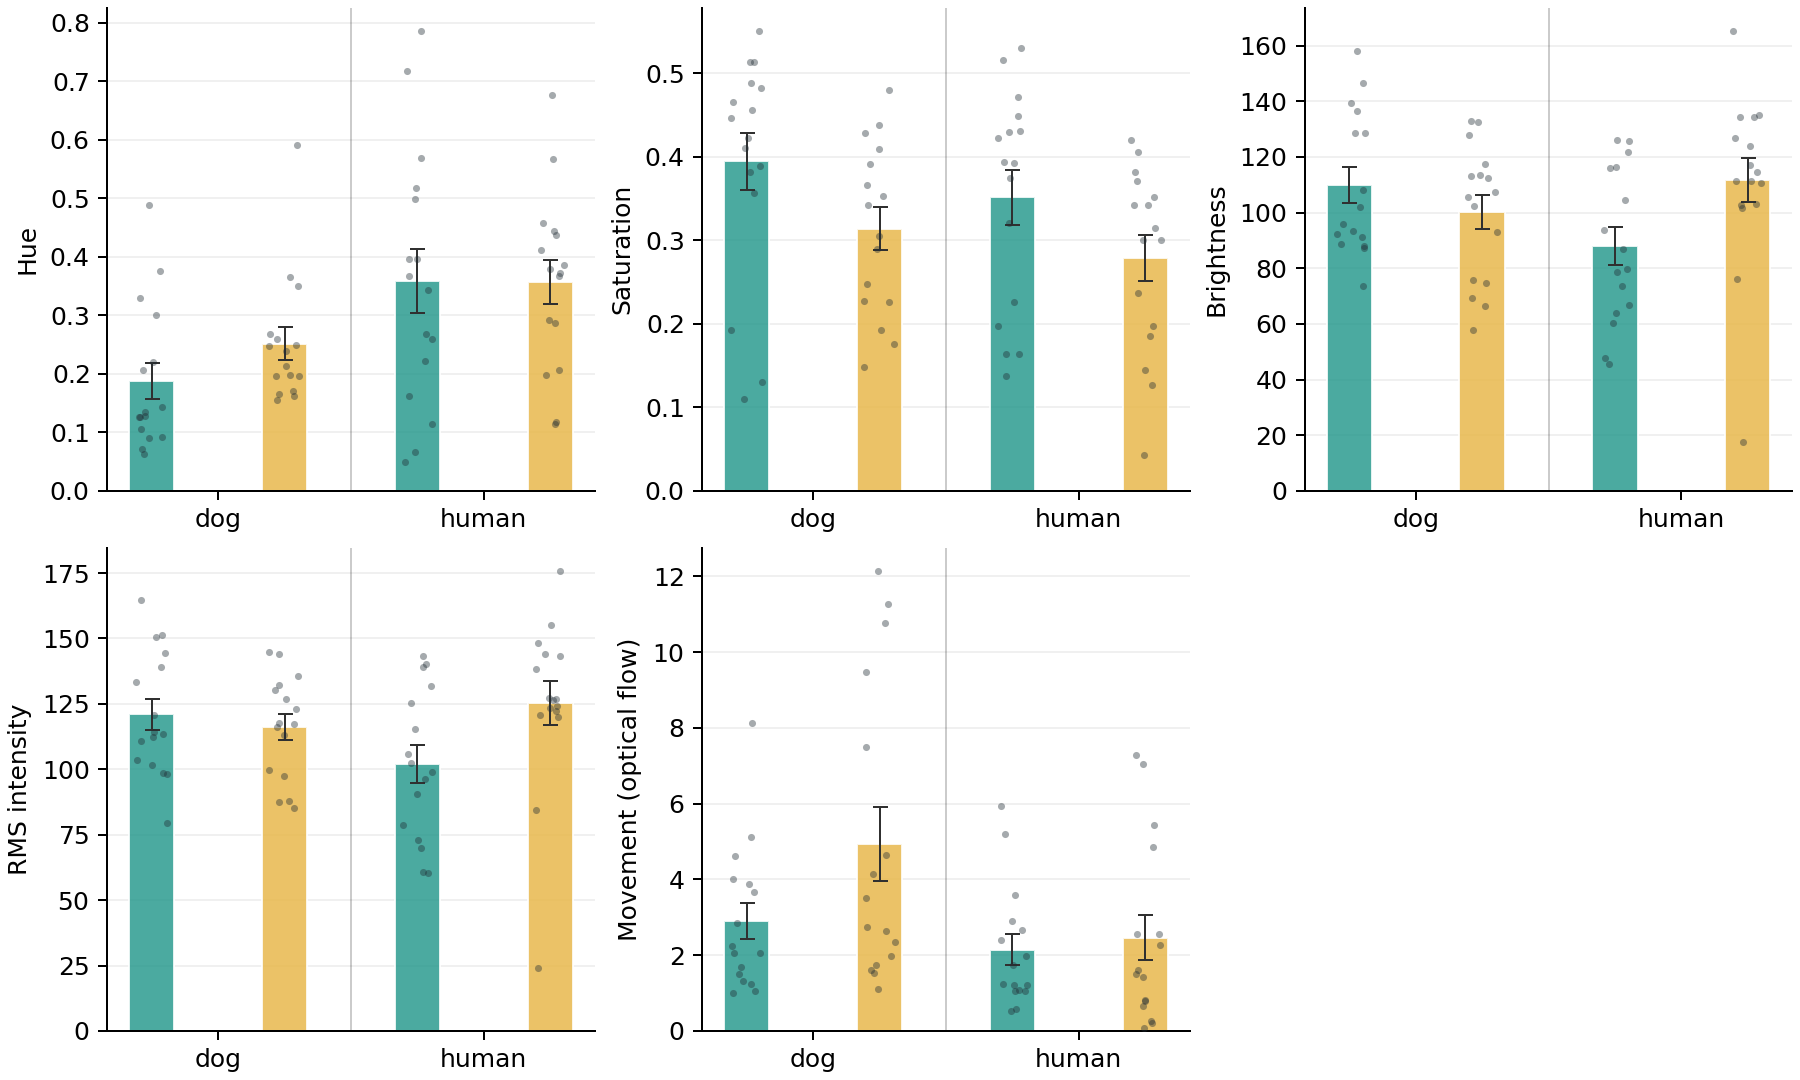

,property,term,sum_sq,df,F,p,residual_df,partial_eta_squared,p_fdr_bh_within_term,p_fdr_bh_all_terms
0,hue,species,3.051343e-01,1.0,1.239137e+01,0.000830,60.0,1.711719e-01,0.008302,0.024905
1,hue,emotion,1.587247e-02,1.0,6.445738e-01,0.425228,60.0,1.062871e-02,0.708714,0.694322
2,hue,species:emotion,1.710616e-02,1.0,6.946734e-01,0.407885,60.0,1.144538e-02,0.723713,0.694322
3,saturation,species,2.415972e-02,1.0,1.652241e+00,0.203594,60.0,2.679936e-02,0.456818,0.508984
4,saturation,emotion,9.338051e-02,1.0,6.386128e+00,0.014155,60.0,9.619672e-02,0.141552,0.109752
5,saturation,species:emotion,2.881076e-04,1.0,1.970317e-02,0.888839,60.0,3.282783e-04,0.992183,1.000000
6,brightness,species,4.275464e+02,1.0,5.633295e-01,0.455855,60.0,9.301495e-03,0.578601,0.694322
7,brightness,emotion,7.747516e+02,1.0,1.020802e+00,0.316386,60.0,1.672876e-02,0.632772,0.632772
8,brightness,species:emotion,4.466680e+03,1.0,5.885239e+00,0.018292,60.0,8.932561e-02,0.182920,0.109752
9,contrast_rms,species,3.930058e+02,1.0,5.458934e-01,0.462881,60.0,9.016191e-03,0.578601,0.694322


,property,group_a,group_b,n_a,n_b,mean_a,mean_b,sem_a,sem_b,difference_a_minus_b,difference_ci95_low,difference_ci95_high,t,df,p,hedges_g,p_fdr_bh_all,p_holm_within_property
0,hue,DogP,DogH,16,16,1.878346e-01,2.520287e-01,0.030972,0.027408,-0.064194,-1.487101e-01,2.032183e-02,-1.552172,29.562496,0.131262,-0.534941,0.399481,0.287217
5,hue,HumP,HumH,16,16,3.586296e-01,3.574285e-01,0.054781,0.038010,0.001201,-1.356733e-01,1.380755e-01,0.018014,26.725221,0.985761,0.006208,1.000000,0.985761
6,saturation,DogP,DogH,16,16,3.942847e-01,3.136457e-01,0.033869,0.025619,0.080639,-6.359694e-03,1.676377e-01,1.898877,27.931264,0.067955,0.654429,0.303312,0.339777
11,saturation,HumP,HumH,16,16,3.511828e-01,2.790307e-01,0.032945,0.027691,0.072152,-1.585027e-02,1.601545e-01,1.676515,29.137946,0.104336,0.577795,0.368245,0.417344
12,brightness,DogP,DogH,16,16,1.098365e+02,1.000868e+02,6.410493,6.102120,9.749717,-8.327133e+00,2.782657e+01,1.101608,29.927380,0.279413,0.379659,0.620918,0.793353
17,brightness,HumP,HumH,16,16,8.795893e+01,1.116258e+02,6.907363,7.981156,-23.666896,-4.524195e+01,-2.091841e+00,-2.242220,29.394714,0.032653,-0.772759,0.231040,0.163653
18,contrast_rms,DogP,DogH,16,16,1.210197e+02,1.161785e+02,5.925333,4.923792,4.841281,-1.091475e+01,2.059731e+01,0.628402,29.027159,0.534654,0.216573,0.912537,1.000000
23,contrast_rms,HumP,HumH,16,16,1.019857e+02,1.253003e+02,7.117928,8.364489,-23.314663,-4.576935e+01,-8.599765e-01,-2.122766,29.251242,0.042357,-0.731591,0.231040,0.254144
24,block_motion_total,DogP,DogH,16,16,3.247748e+06,3.734505e+06,504756.931561,358126.878656,-486757.187500,-1.756524e+06,7.830092e+05,-0.786490,27.048651,0.438417,-0.271056,0.773677,1.000000
29,block_motion_total,HumP,HumH,16,16,3.100752e+06,2.856306e+06,500197.216684,478985.741519,244446.812500,-1.170039e+06,1.658932e+06,0.352967,29.943847,0.726586,0.121647,1.000000,1.000000


,property,group_a,group_b,n_a,n_b,mean_a,mean_b,sem_a,sem_b,difference_a_minus_b,difference_ci95_low,difference_ci95_high,t,df,p,hedges_g,p_fdr_bh_all,p_holm_within_property
0,hue,DogP,DogH,16,16,1.878346e-01,2.520287e-01,0.030972,0.027408,-0.064194,-1.487101e-01,2.032183e-02,-1.552172,29.562496,0.131262,-0.534941,0.399481,0.287217
1,hue,DogP,HumP,16,16,1.878346e-01,3.586296e-01,0.030972,0.054781,-0.170795,-3.007641e-01,-4.082594e-02,-2.714026,23.700529,0.012188,-0.935363,0.183998,0.060941
2,hue,DogP,HumH,16,16,1.878346e-01,3.574285e-01,0.030972,0.038010,-0.169594,-2.698997e-01,-6.928814e-02,-3.458926,28.824455,0.001707,-1.192085,0.102443,0.010244
3,hue,DogH,HumP,16,16,2.520287e-01,3.586296e-01,0.027408,0.054781,-0.106601,-2.336137e-01,2.041185e-02,-1.740282,22.066625,0.095739,-0.599771,0.359021,0.287217
4,hue,DogH,HumH,16,16,2.520287e-01,3.574285e-01,0.027408,0.038010,-0.105400,-2.015043e-01,-9.295240e-03,-2.249208,27.278794,0.032770,-0.775168,0.231040,0.131081
5,hue,HumP,HumH,16,16,3.586296e-01,3.574285e-01,0.054781,0.038010,0.001201,-1.356733e-01,1.380755e-01,0.018014,26.725221,0.985761,0.006208,1.000000,0.985761
6,saturation,DogP,DogH,16,16,3.942847e-01,3.136457e-01,0.033869,0.025619,0.080639,-6.359694e-03,1.676377e-01,1.898877,27.931264,0.067955,0.654429,0.303312,0.339777
7,saturation,DogP,HumP,16,16,3.942847e-01,3.511828e-01,0.033869,0.032945,0.043102,-5.339698e-02,1.396008e-01,0.912225,29.977083,0.368929,0.314389,0.683654,1.000000
8,saturation,DogP,HumH,16,16,3.942847e-01,2.790307e-01,0.033869,0.027691,0.115254,2.576007e-02,2.047481e-01,2.634484,28.860447,0.013407,0.907949,0.183998,0.080440
9,saturation,DogH,HumP,16,16,3.136457e-01,3.511828e-01,0.025619,0.032945,-0.037537,-1.229858e-01,4.791171e-02,-0.899445,28.283474,0.376010,-0.309985,0.683654,1.000000


In [8]:
display(Image(filename=str(FIGURE_DIRECTORY / 'properties_all_categories_by_species.png'), width=1100))
display(tables['anova_species_emotion'])
# The principal P/H contrast within each species:
pairs = tables['ttest_four_groups']
display(pairs[((pairs.group_a == 'DogP') & (pairs.group_b == 'DogH')) |
              ((pairs.group_a == 'HumP') & (pairs.group_b == 'HumH'))])
# All six pairs for each property:
display(pairs)

## Diagnostics, run adjustment, and provenance
Levene tests probe unequal variances; Shapiro tests probe residual normality. Small diagnostic p-values warrant caution with classical ANOVA. The run-adjusted model is a sensitivity analysis. Non-significance does not establish equivalence.

In [9]:
display(tables['anova_diagnostics'])
display(tables['anova_run_adjusted'])
display(json.loads((OUTPUT / 'provenance.json').read_text(encoding='utf-8')))
display(pd.DataFrame({'file': [p.name for p in sorted(OUTPUT.iterdir()) if p.is_file()]}))

,property,levene_statistic,levene_p,shapiro_residual_W,shapiro_residual_p
0,hue,2.932333,0.040637,0.959582,0.034758
1,saturation,0.165369,0.919297,0.934819,0.002193
2,brightness,0.146392,0.931607,0.970740,0.132178
3,contrast_rms,0.496994,0.685755,0.954865,0.019994
4,block_motion_total,0.635952,0.594770,0.963355,0.054461
5,block_motion_mean_per_transition,3.147833,0.031470,0.968044,0.095645
6,dense_flow_pixels_per_frame,2.557023,0.063546,0.900278,0.000082
7,dense_flow_percent_diagonal_per_second,2.590212,0.061078,0.900957,0.000087
8,number_of_frames,1.473444,0.230822,0.971983,0.153352
9,duration_seconds,1.473444,0.230822,0.971983,0.153352


,property,term,sum_sq,df,F,p,residual_df,partial_eta_squared,p_fdr_bh_within_term,p_fdr_bh_all_terms
0,hue,species,3.051343e-01,1.0,1.265131e+01,0.000764,57.0,1.816378e-01,0.007637,0.022910
1,hue,emotion,1.587247e-02,1.0,6.580955e-01,0.420608,57.0,1.141376e-02,0.701013,0.666004
2,hue,species:emotion,1.710616e-02,1.0,7.092461e-01,0.403214,57.0,1.228999e-02,0.740005,0.666004
3,saturation,species,2.415972e-02,1.0,1.694059e+00,0.198303,57.0,2.886253e-02,0.473951,0.510587
4,saturation,emotion,9.338051e-02,1.0,6.547761e+00,0.013182,57.0,1.030368e-01,0.131816,0.110944
5,saturation,species:emotion,2.881076e-04,1.0,2.020186e-02,0.887476,57.0,3.542929e-04,0.992382,1.000000
6,brightness,species,4.275464e+02,1.0,6.495478e-01,0.423624,57.0,1.126718e-02,0.542093,0.666004
7,brightness,emotion,7.747516e+02,1.0,1.177038e+00,0.282527,57.0,2.023200e-02,0.565055,0.568741
8,brightness,species:emotion,4.466680e+03,1.0,6.785982e+00,0.011698,57.0,1.063867e-01,0.116984,0.110944
9,contrast_rms,species,3.930058e+02,1.0,6.217238e-01,0.433675,57.0,1.078975e-02,0.542093,0.666004


{'frames_root': 'G:\\My Drive\\Networks\\stimuli_by_frames',
 'video_root': 'C:\\github\\Networks\\paradigm\\stimuli',
 'output': 'C:\\github\\dog_brain_toolkit\\outputs\\video_properties',
 'method_version': 1,
 'analysis_sha256': 'e682719a87ebec3794a5f32de7067510080c3a76e9ac1b90de1cb4c2c8998429',
 'n_videos': 240,
 'n_frames': 21619,
 'n_unique_clips': 160,
 'duplicate_policy': 'Retain all folder measurements; one observation per unique byte-identical frame sequence for plots and tests',
 'n_transitions': 21379,
 'max_flow_dimension': 640,
 'workers': 4,
 'fps_override': None,
 'opencv_version': '4.11.0',
 'numpy_version': '1.26.3',
 'python': '3.11.5 | packaged by Anaconda, Inc. | (main, Sep 11 2023, 13:26:23) [MSC v.1916 64 bit (AMD64)]',
 'farneback_parameters': [0.5, 3, 15, 3, 5, 1.2, 0],
 'block_match': 'Python TSS reproduction: 35x35, MSE, +/-7, steps 4/2/1, zero-padded edges, center-first ties; not MATLAB-validated',
 'matlab_source': 'https://github.com/rhernandez00/Comparati

,file
0,anova_diagnostics.csv
1,anova_run_adjusted.csv
2,anova_species_emotion.csv
3,condition_counts.csv
4,duplicate_sequences.csv
5,figure_layout_check.png
6,frame_properties.csv
7,group_summary.csv
8,input_file_inventory.csv
9,measurement_source_before_plot_update.json


## Publication tables: P/H comparisons

All tests are two-sided. The sampling unit is a unique clip; exact repeated frame sequences count once. Welch independent two-sample tests compare pooled P/H and all six pairs of DogP, DogH, HumP, HumH. ANOVA uses type III sums of squares, sum contrasts, and species × emotion; a separate sensitivity analysis adds first-occurrence run. Tables include every measured outcome to preserve the prespecified multiple-testing families, even when an outcome is omitted from plots.

Means ± SEM describe unique clips. Welch tables give group sizes, means, SEMs, signed differences, 95% confidence intervals, t, Welch df, raw p, adjusted p, and Hedges g. ANOVA tables give numerator/residual df, F, raw/adjusted p, and partial eta squared. BH correction is across ten outcomes for pooled tests, across ten outcomes per ANOVA term (and also across all 30 ANOVA tests); pairwise tests include Holm across six comparisons per outcome and BH across all 60 tests. Confidence intervals are unadjusted. Diagnostics report median-centered Levene and Shapiro tests of ANOVA residuals; classical ANOVA assumptions warrant checking, especially for skewed flow outcomes. Distinct clips may still share actors/source recordings, which these tests do not model.

In [10]:
# Print full publication tables without truncating rows or columns.
publication_tables = {
    'Descriptive statistics (mean, SD, SEM)': tables['group_summary'],
    'Pooled P versus H: two-sided Welch t-test': tables['ttest_pooled_P_vs_H'],
    'Four-group pairwise comparisons: two-sided Welch t-tests': tables['ttest_four_groups'],
    'Two-way ANOVA: species, emotion, interaction': tables['anova_species_emotion'],
    'Run-adjusted ANOVA sensitivity analysis': tables['anova_run_adjusted'],
    'ANOVA variance and normality diagnostics': tables['anova_diagnostics'],
}
html_sections = []
with pd.option_context('display.max_rows', None, 'display.max_columns', None, 'display.width', 240):
    for title, table in publication_tables.items():
        display(Markdown('### ' + title))
        display(table.style.format(precision=5))
        html_sections.append('<h2>' + title + '</h2>' + table.to_html(index=False, float_format=lambda x: f'{x:.6g}'))
        safe_name = title.split(':')[0].lower().replace(' ', '_').replace('/', '_')
        table.to_csv(OUTPUT / ('publication_' + safe_name + '.csv'), index=False)
(OUTPUT / 'publication_statistical_tables.html').write_text(
    '<!doctype html><meta charset="utf-8"><title>P/H statistical results</title>' +
    '<p>Unique clips; two-sided Welch tests; type III species × emotion ANOVA. See notebook for correction families and assumptions.</p>' +
    ''.join(html_sections), encoding='utf-8')
print('Publication tables exported to:', OUTPUT / 'publication_statistical_tables.html')

### Descriptive statistics (mean, SD, SEM)

,comparison,group,property,n,mean,sd,sem
0,pooled,H,hue,32,0.30473,0.14095,0.02492
1,pooled,H,saturation,32,0.29634,0.10643,0.01881
2,pooled,H,brightness,32,105.85632,28.56206,5.04911
3,pooled,H,contrast_rms,32,120.73940,27.40125,4.84390
4,pooled,H,block_motion_total,32,3295405.50000,1722840.94518,304558.12881
5,pooled,H,block_motion_mean_per_transition,32,38531.23823,19362.15715,3422.77816
6,pooled,H,dense_flow_pixels_per_frame,32,3.70346,3.42831,0.60605
7,pooled,H,dense_flow_percent_diagonal_per_second,32,12.27536,11.36335,2.00877
8,pooled,H,number_of_frames,32,90.00000,28.11382,4.96987
9,pooled,H,duration_seconds,32,3.00000,0.93713,0.16566


### Pooled P versus H: two-sided Welch t-test

,property,group_a,group_b,n_a,n_b,mean_a,mean_b,sem_a,sem_b,difference_a_minus_b,difference_ci95_low,difference_ci95_high,t,df,p,hedges_g,p_fdr_bh
0,hue,P,H,32,32,0.27323,0.30473,0.03455,0.02492,-0.03150,-0.11681,0.05382,-0.73946,56.38512,0.46269,-0.18262,0.75019
1,saturation,P,H,32,32,0.37273,0.29634,0.02356,0.01881,0.07640,0.01607,0.13672,2.53379,59.10646,0.01395,0.62575,0.13955
2,brightness,P,H,32,32,98.89773,105.85632,5.03441,5.04911,-6.95859,-21.21152,7.29434,-0.97594,61.99947,0.33289,-0.24102,0.66577
3,contrast_rms,P,H,32,32,111.50271,120.73940,4.86556,4.84390,-9.23669,-22.96092,4.48753,-1.34535,61.99877,0.18341,-0.33225,0.45853
4,block_motion_total,P,H,32,32,3174250.31250,3295405.50000,349780.02596,304558.12881,-121155.18750,-1048608.51053,806298.13553,-0.26123,60.84850,0.79480,-0.06451,0.99350
5,block_motion_mean_per_transition,P,H,32,32,35436.43026,38531.23823,3425.82977,3422.77816,-3094.80797,-12775.22267,6585.60673,-0.63907,61.99995,0.52513,-0.15783,0.75019
6,dense_flow_pixels_per_frame,P,H,32,32,2.52598,3.70346,0.31457,0.60605,-1.17748,-2.55147,0.19651,-1.72444,46.57328,0.09126,-0.42587,0.31040
7,dense_flow_percent_diagonal_per_second,P,H,32,32,8.39609,12.27536,1.04177,2.00877,-3.87927,-8.43268,0.67414,-1.71434,46.55031,0.09312,-0.42338,0.31040
8,number_of_frames,P,H,32,32,90.00000,90.00000,3.78851,4.96987,0.00000,-12.50943,12.50943,0.00000,57.93330,1.00000,0.00000,1.00000
9,duration_seconds,P,H,32,32,3.00000,3.00000,0.12628,0.16566,0.00000,-0.41698,0.41698,0.00000,57.93330,1.00000,0.00000,1.00000


### Four-group pairwise comparisons: two-sided Welch t-tests

,property,group_a,group_b,n_a,n_b,mean_a,mean_b,sem_a,sem_b,difference_a_minus_b,difference_ci95_low,difference_ci95_high,t,df,p,hedges_g,p_fdr_bh_all,p_holm_within_property
0,hue,DogP,DogH,16,16,0.18783,0.25203,0.03097,0.02741,-0.06419,-0.14871,0.02032,-1.55217,29.56250,0.13126,-0.53494,0.39948,0.28722
1,hue,DogP,HumP,16,16,0.18783,0.35863,0.03097,0.05478,-0.17080,-0.30076,-0.04083,-2.71403,23.70053,0.01219,-0.93536,0.18400,0.06094
2,hue,DogP,HumH,16,16,0.18783,0.35743,0.03097,0.03801,-0.16959,-0.26990,-0.06929,-3.45893,28.82445,0.00171,-1.19209,0.10244,0.01024
3,hue,DogH,HumP,16,16,0.25203,0.35863,0.02741,0.05478,-0.10660,-0.23361,0.02041,-1.74028,22.06662,0.09574,-0.59977,0.35902,0.28722
4,hue,DogH,HumH,16,16,0.25203,0.35743,0.02741,0.03801,-0.10540,-0.20150,-0.00930,-2.24921,27.27879,0.03277,-0.77517,0.23104,0.13108
5,hue,HumP,HumH,16,16,0.35863,0.35743,0.05478,0.03801,0.00120,-0.13567,0.13808,0.01801,26.72522,0.98576,0.00621,1.00000,0.98576
6,saturation,DogP,DogH,16,16,0.39428,0.31365,0.03387,0.02562,0.08064,-0.00636,0.16764,1.89888,27.93126,0.06796,0.65443,0.30331,0.33978
7,saturation,DogP,HumP,16,16,0.39428,0.35118,0.03387,0.03295,0.04310,-0.05340,0.13960,0.91222,29.97708,0.36893,0.31439,0.68365,1.00000
8,saturation,DogP,HumH,16,16,0.39428,0.27903,0.03387,0.02769,0.11525,0.02576,0.20475,2.63448,28.86045,0.01341,0.90795,0.18400,0.08044
9,saturation,DogH,HumP,16,16,0.31365,0.35118,0.02562,0.03295,-0.03754,-0.12299,0.04791,-0.89945,28.28347,0.37601,-0.30999,0.68365,1.00000


... (3 outputs left out)

,property,term,sum_sq,df,F,p,residual_df,partial_eta_squared,p_fdr_bh_within_term,p_fdr_bh_all_terms
0,hue,species,0.30513,1.00000,12.65131,0.00076,57.00000,0.18164,0.00764,0.02291
1,hue,emotion,0.01587,1.00000,0.65810,0.42061,57.00000,0.01141,0.70101,0.66600
2,hue,species:emotion,0.01711,1.00000,0.70925,0.40321,57.00000,0.01229,0.74000,0.66600
3,saturation,species,0.02416,1.00000,1.69406,0.19830,57.00000,0.02886,0.47395,0.51059
4,saturation,emotion,0.09338,1.00000,6.54776,0.01318,57.00000,0.10304,0.13182,0.11094
5,saturation,species:emotion,0.00029,1.00000,0.02020,0.88748,57.00000,0.00035,0.99238,1.00000
6,brightness,species,427.54638,1.00000,0.64955,0.42362,57.00000,0.01127,0.54209,0.66600
7,brightness,emotion,774.75157,1.00000,1.17704,0.28253,57.00000,0.02023,0.56505,0.56874
8,brightness,species:emotion,4466.68012,1.00000,6.78598,0.01170,57.00000,0.10639,0.11698,0.11094
9,contrast_rms,species,393.00583,1.00000,0.62172,0.43367,57.00000,0.01079,0.54209,0.66600


### ANOVA variance and normality diagnostics

,property,levene_statistic,levene_p,shapiro_residual_W,shapiro_residual_p
0,hue,2.93233,0.04064,0.95958,0.03476
1,saturation,0.16537,0.91930,0.93482,0.00219
2,brightness,0.14639,0.93161,0.97074,0.13218
3,contrast_rms,0.49699,0.68575,0.95486,0.01999
4,block_motion_total,0.63595,0.59477,0.96335,0.05446
5,block_motion_mean_per_transition,3.14783,0.03147,0.96804,0.09564
6,dense_flow_pixels_per_frame,2.55702,0.06355,0.90028,0.00008
7,dense_flow_percent_diagonal_per_second,2.59021,0.06108,0.90096,0.00009
8,number_of_frames,1.47344,0.23082,0.97198,0.15335
9,duration_seconds,1.47344,0.23082,0.97198,0.15335


Publication tables exported to: C:\github\dog_brain_toolkit\outputs\video_properties\publication_statistical_tables.html
